
# Chapter 5: Classification

## Objectives
This chapter explores classification as a supervised machine learning
task. The notebook demonstrates data exploration, model training,
classification evaluation, and interpretation of results.

## Learning Outcomes
- Understand the concept of classification.
- Distinguish features and target labels.
- Train a Logistic Regression classifier.
- Evaluate model performance using classification metrics.
- Interpret a confusion matrix.



## 1. Theoretical Background

Classification is a supervised learning method used to predict
categorical outcomes based on input features.

The model learns the relationship between features (X) and target
labels (y) from labeled training data.

Common classification algorithms include Logistic Regression,
Decision Trees, K-Nearest Neighbors, Naive Bayes, and Random Forest.

Important evaluation metrics:

- Accuracy: proportion of all predictions that are correct.
- Precision: proportion of predicted positive cases that are truly positive.
- Recall: proportion of actual positive cases correctly identified.
- F1-score: harmonic mean of precision and recall.
- Confusion Matrix: summarizes correct and incorrect predictions
  for each class.

The choice of evaluation metric depends on the problem and the
consequences of different types of prediction errors.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [2]:

# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of observations:", X.shape[0])
print("Target classes:", data.target_names)


Dataset shape: (569, 30)
Number of features: 30
Number of observations: 569
Target classes: ['malignant' 'benign']



## 2. Dataset Description

This notebook uses the Breast Cancer Wisconsin dataset provided
by Scikit-learn.

The dataset contains numerical features computed from digitized
images of breast mass samples. The target contains two classes:
malignant and benign.

In this dataset:
- X represents the input features.
- y represents the target labels.
- Target 0 represents malignant.
- Target 1 represents benign.

This dataset is used only for educational machine learning
experiments and is not intended for clinical diagnosis.


In [3]:

# Display the first five observations
print("First five observations:")
display(X.head())

# Display descriptive statistics
print("Descriptive statistics:")
display(X.describe().T.head(10))

# Check missing values
print("Total missing values:", X.isnull().sum().sum())

# Display class distribution
class_distribution = (
    y.map(dict(enumerate(data.target_names)))
     .value_counts()
)

print("\nClass distribution:")
display(class_distribution)


First five observations:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


Total missing values: 0

Class distribution:


,count
target,
benign,357
malignant,212


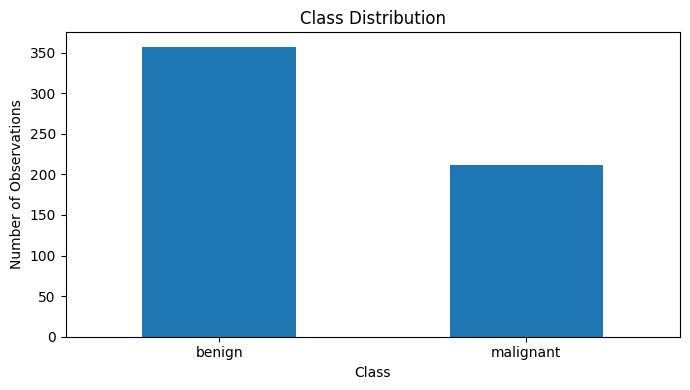

In [4]:

class_distribution.plot(kind="bar", figsize=(7, 4))

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset
before building a classification model.

The head() method displays sample observations, while describe()
provides descriptive statistics such as the mean, standard
deviation, minimum, and maximum.

Checking missing values helps identify potential data quality
problems. The class distribution plot shows how many observations
belong to each target category.

EDA is important because the characteristics of the dataset
can influence model selection and evaluation.


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 455
Testing samples: 114



## 4. Training and Testing Data

The dataset is divided into training and testing subsets.

The training set contains 80% of the observations and is used
to fit the model. The testing set contains the remaining 20%
and is used to evaluate predictions on unseen observations.

The stratify parameter preserves the approximate class
proportions in both subsets.

The random_state parameter makes the split reproducible.


In [6]:

# Build a pipeline that standardizes features and trains
# a Logistic Regression classifier.

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

model.fit(X_train, y_train)

print("Model training completed.")


Model training completed.



## 5. Logistic Regression

Logistic Regression is a classification algorithm that estimates
the probability of a categorical outcome.

For binary classification, the logistic function transforms a
linear combination of features into a probability between 0 and 1.

The model predicts a class using a decision threshold, commonly 0.5.

StandardScaler standardizes numerical features. It is included in
the pipeline so that the scaling parameters are learned only from
the training data and then applied to the testing data.

The max_iter parameter sets the maximum number of optimization
iterations allowed for model fitting.


In [7]:

y_pred = model.predict(X_test)

print("First 10 actual labels:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])


First 10 actual labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 predicted labels:
[0 1 0 1 0 1 1 0 0 0]


In [8]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-score : 0.9861


In [9]:

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    )
)


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



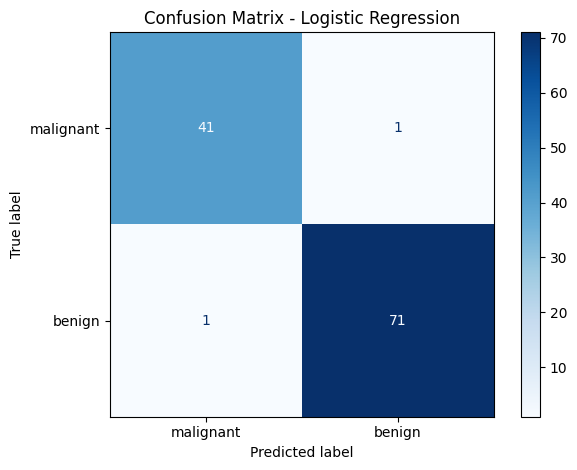

In [10]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()



## 6. Model Evaluation

Accuracy measures the overall proportion of correct predictions.
However, accuracy alone may be insufficient when classes are
imbalanced or when different errors have different consequences.

Precision measures how many predicted positive cases are actually
positive. Recall measures how many actual positive cases are
correctly identified. F1-score balances precision and recall.

The classification report presents precision, recall, F1-score,
and support for each class.

The confusion matrix compares actual and predicted classes.
Its diagonal entries represent correct predictions, while
off-diagonal entries represent classification errors.

In this dataset, the positive label is 1 (benign). Therefore,
precision and recall calculated with the default binary setting
refer to the benign class. The classification report provides
metrics for both classes.



## 7. Conclusion

Classification is a supervised learning approach for predicting
categorical outcomes from labeled data.

In this experiment, Logistic Regression was trained using the
Breast Cancer Wisconsin dataset. Standardization was applied
through a pipeline, and model performance was evaluated using
accuracy, precision, recall, F1-score, and a confusion matrix.

The experiment demonstrates that model evaluation should consider
multiple metrics to understand both correct predictions and errors.

The results describe performance on this particular test split
and do not establish clinical suitability or general performance
on all datasets.
